<a href="https://colab.research.google.com/github/karenkatherine/Karenkatherine/blob/main/Proyecto_Final_Comercial_Andina_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [184]:
df = pd.read_csv('/content/comercial_andina_2M.csv')

In [185]:
df.shape

(2000000, 8)

In [186]:
df.head()

,id_transaccion,fecha,sucursal,categoria,ventas,precio_unitario,promo,descuento_pct
0,1,2025-09-15,Quito-Norte,Hogar,61.93,141.22,0,0.0
1,2,2025-10-10,Guayaquil-Centro,Cuidado Personal,122.08,31.42,1,39.6
2,3,2025-03-19,Guayaquil-Centro,Limpieza,143.58,25.14,1,28.4
3,4,2025-11-30,Ambato-Centro,Alimentos,58.55,96.70,0,0.0
4,5,2025-01-30,Guayaquil-Centro,Hogar,138.54,86.27,1,16.9


In [187]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 8 columns):
 #   Column           Dtype  
---  ------           -----  
 0   id_transaccion   int64  
 1   fecha            object 
 2   sucursal         object 
 3   categoria        object 
 4   ventas           float64
 5   precio_unitario  float64
 6   promo            int64  
 7   descuento_pct    float64
dtypes: float64(3), int64(2), object(3)
memory usage: 122.1+ MB


In [188]:
df.isnull().sum()

,0
id_transaccion,0
fecha,0
sucursal,0
categoria,0
ventas,0
precio_unitario,0
promo,0
descuento_pct,199239


In [189]:
df.duplicated().sum()

np.int64(0)

In [190]:
df['fecha'] = pd.to_datetime(df['fecha'])

In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 8 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id_transaccion   int64         
 1   fecha            datetime64[ns]
 2   sucursal         object        
 3   categoria        object        
 4   ventas           float64       
 5   precio_unitario  float64       
 6   promo            int64         
 7   descuento_pct    float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(2)
memory usage: 122.1+ MB


In [192]:
df['año'] = df['fecha'].dt.year
df['mes'] = df['fecha'].dt.month
df['dia'] = df['fecha'].dt.day

In [193]:
df['semana'] = df['fecha'].dt.isocalendar().week

In [194]:
df.describe()

,id_transaccion,fecha,ventas,precio_unitario,promo,descuento_pct,año,mes,dia,semana
count,2.000000e+06,2000000,2.000000e+06,2.000000e+06,2.000000e+06,1.800761e+06,2000000.0,2.000000e+06,2.000000e+06,2000000.0
mean,1.000000e+06,2025-07-02 01:20:10.535999744,8.246998e+01,1.515510e+02,2.999580e-01,6.755129e+00,2025.0,6.527999e+00,1.571720e+01,26.435733
min,1.000000e+00,2025-01-01 00:00:00,5.000000e+00,3.000000e+00,0.000000e+00,0.000000e+00,2025.0,1.000000e+00,1.000000e+00,1.0
25%,5.000008e+05,2025-04-02 00:00:00,4.370000e+01,7.737000e+01,0.000000e+00,0.000000e+00,2025.0,4.000000e+00,8.000000e+00,13.0
50%,1.000000e+06,2025-07-02 00:00:00,8.244000e+01,1.516100e+02,0.000000e+00,0.000000e+00,2025.0,7.000000e+00,1.600000e+01,26.0
75%,1.500000e+06,2025-10-01 00:00:00,1.212000e+02,2.256900e+02,1.000000e+00,1.090000e+01,2025.0,1.000000e+01,2.300000e+01,39.0
max,2.000000e+06,2025-12-31 00:00:00,1.600000e+02,3.000000e+02,1.000000e+00,4.000000e+01,2025.0,1.200000e+01,3.100000e+01,52.0
std,5.773504e+05,NaN,4.474276e+01,8.569055e+01,4.582394e-01,1.170866e+01,0.0,3.446100e+00,8.801356e+00,15.038346


In [195]:
df['ventas'].describe()

,ventas
count,2.000000e+06
mean,8.246998e+01
std,4.474276e+01
min,5.000000e+00
25%,4.370000e+01
50%,8.244000e+01
75%,1.212000e+02
max,1.600000e+02


In [196]:
Q1 = df['ventas'].quantile(0.25)
Q3 = df['ventas'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: -72.55
Límite superior: 237.45


In [197]:
df.groupby('promo')['descuento_pct'].apply(
    lambda x: x.isnull().sum()
)

,descuento_pct
promo,
0,139694
1,59545


# Se realizó un análisis exploratorio de dos millones de transacciones comerciales. Se identificaron valores faltantes en la variable descuento, sin encontrar registros duplicados exactos. Adicionalmente, se normalizó el tipo de dato de fecha y se crearon variables temporales para facilitar la posterior predicción de ventas semanales. El análisis descriptivo y el método IQR permiten evaluar la presencia de posibles valores atípicos antes de aplicar transformaciones adicionales.

In [198]:
df.groupby('promo')['descuento_pct'].describe()

,count,mean,std,min,25%,50%,75%,max
promo,,,,,,,,
0,1260390.0,0.000000,0.00000,0.0,0.0,0.0,0.0,0.0
1,540371.0,22.511149,10.10787,5.0,13.8,22.5,31.3,40.0


In [199]:
df[(df['promo'] == 0) & (df['descuento_pct'] > 0)].shape

(0, 12)

In [200]:
df[(df['promo'] == 1) & (df['descuento_pct'] == 0)].shape

(0, 12)

Análisis de calidad de datos: Mediante el método IQR se evaluó la presencia de valores atípicos en las ventas, sin identificar observaciones fuera de los límites calculados. Posteriormente, se analizaron los valores faltantes de la variable descuento, encontrando 199.239 registros sin información, de los cuales 139.694 corresponden a ventas sin promoción y 59.545 a ventas promocionales. Debido a esta distribución, se determinó que era necesario investigar el comportamiento de los descuentos antes de aplicar cualquier imputación.

In [201]:
df.loc[
    (df['promo'] == 0) & (df['descuento_pct'].isnull()),
    'descuento_pct'
] = 0

In [202]:
df.isnull().sum()

,0
id_transaccion,0
fecha,0
sucursal,0
categoria,0
ventas,0
precio_unitario,0
promo,0
descuento_pct,59545
año,0
mes,0


In [203]:
df.groupby('promo')['descuento_pct'].apply(
    lambda x: x.isnull().sum()
)

,descuento_pct
promo,
0,0
1,59545


Tratamiento de valores faltantes: Se identificaron 199.239 valores nulos en la variable descuento_pct. El análisis por grupos evidenció que todos los descuentos conocidos correspondientes a transacciones sin promoción eran iguales a cero. Por esta razón, se imputaron con cero los 139.694 valores faltantes de dicho grupo. Los 59.545 descuentos faltantes de transacciones promocionales se conservaron como nulos, debido a que no existe información suficiente para determinar su valor real. Esta decisión evita introducir descuentos artificiales y preserva la integridad de la información.

In [204]:
df[['ventas', 'precio_unitario']].describe()

,ventas,precio_unitario
count,2.000000e+06,2.000000e+06
mean,8.246998e+01,1.515510e+02
std,4.474276e+01,8.569055e+01
min,5.000000e+00,3.000000e+00
25%,4.370000e+01,7.737000e+01
50%,8.244000e+01,1.516100e+02
75%,1.212000e+02,2.256900e+02
max,1.600000e+02,3.000000e+02


In [205]:
df[df['ventas'] <= 0].shape

(0, 12)

In [206]:
df[df['precio_unitario'] <= 0].shape

(0, 12)

In [207]:
df[(df['descuento_pct'] < 0) | (df['descuento_pct'] > 100)].shape

(0, 12)

In [208]:
df['sucursal'].value_counts()

,count
sucursal,
Guayaquil-Centro,334021
Cuenca-Este,333808
Quito-Norte,333728
Ambato-Centro,333142
Quito-Sur,332744
Manta-Puerto,332557


In [209]:
df['categoria'].value_counts()

,count
categoria,
Alimentos,400476
Cuidado Personal,400126
Electrónica,400113
Limpieza,399757
Hogar,399528


In [210]:
df['promo'].value_counts(dropna=False)

,count
promo,
0,1400084
1,599916


In [211]:
df['fecha'].isnull().sum()

np.int64(0)

In [212]:
df['id_transaccion'].duplicated().sum()

np.int64(0)

In [213]:
df['fecha'].min()

Timestamp('2025-01-01 00:00:00')

In [214]:
df['fecha'].max()

Timestamp('2025-12-31 00:00:00')

In [215]:
df['año'].value_counts()

,count
año,
2025,2000000


Validación de variables categóricas y temporales: Se verificó la distribución de las transacciones en seis sucursales y cinco categorías comerciales, sin identificar inconsistencias evidentes en sus denominaciones. Asimismo, se comprobó que el indicador de promoción contiene únicamente valores 0 y 1, y que la columna fecha no presenta valores nulos. Estas verificaciones permiten avanzar hacia la consolidación semanal de ventas.

In [216]:
df['inicio_semana'] = (
    df['fecha'] - pd.to_timedelta(df['fecha'].dt.weekday, unit='D')
)

In [217]:
ventas_semanales = df.groupby(
    ['inicio_semana', 'sucursal', 'categoria']
).agg(
    ventas_totales=('ventas', 'sum'),
    transacciones=('id_transaccion', 'count')
).reset_index()

In [218]:
ventas_semanales.head()

,inicio_semana,sucursal,categoria,ventas_totales,transacciones
0,2024-12-30,Ambato-Centro,Alimentos,79650.83,964
1,2024-12-30,Ambato-Centro,Cuidado Personal,78491.43,959
2,2024-12-30,Ambato-Centro,Electrónica,74973.51,886
3,2024-12-30,Ambato-Centro,Hogar,72293.84,872
4,2024-12-30,Ambato-Centro,Limpieza,71944.01,867


In [219]:
ventas_semanales.shape

(1590, 5)

In [220]:
print("Ventas originales:", df['ventas'].sum())
print("Ventas agrupadas:", ventas_semanales['ventas_totales'].sum())

Ventas originales: 164939964.60999998
Ventas agrupadas: 164939964.61


In [221]:
df.groupby('inicio_semana')['fecha'].nunique()

,fecha
inicio_semana,
2024-12-30,5
2025-01-06,7
2025-01-13,7
2025-01-20,7
2025-01-27,7
2025-02-03,7
2025-02-10,7
2025-02-17,7
2025-02-24,7


In [222]:
df.groupby('inicio_semana')['fecha'].nunique().head()

,fecha
inicio_semana,
2024-12-30,5
2025-01-06,7
2025-01-13,7
2025-01-20,7
2025-01-27,7


In [223]:
df.groupby('inicio_semana')['fecha'].nunique().tail()

,fecha
inicio_semana,
2025-12-01,7
2025-12-08,7
2025-12-15,7
2025-12-22,7
2025-12-29,3


In [224]:
ventas_semanales.isnull().sum()

,0
inicio_semana,0
sucursal,0
categoria,0
ventas_totales,0
transacciones,0


Consolidación de ventas semanales: Se agruparon 2.000.000 de transacciones comerciales por semana, sucursal y categoría, obteniendo 1.590 registros agregados. Se comprobó que las ventas totales antes y después de la transformación ascienden a $164.939.964,61, sin pérdidas de información monetaria. La agrupación permitió transformar los datos transaccionales en una estructura adecuada para el análisis predictivo de ventas semanales.

In [225]:
dias_semana = df.groupby('inicio_semana')['fecha'].nunique().reset_index()

dias_semana.columns = ['inicio_semana', 'dias_registrados']

dias_semana.head()

,inicio_semana,dias_registrados
0,2024-12-30,5
1,2025-01-06,7
2,2025-01-13,7
3,2025-01-20,7
4,2025-01-27,7


In [226]:
ventas_semanales = ventas_semanales.merge(
    dias_semana,
    on='inicio_semana',
    how='left'
)

ventas_semanales.head()

,inicio_semana,sucursal,categoria,ventas_totales,transacciones,dias_registrados
0,2024-12-30,Ambato-Centro,Alimentos,79650.83,964,5
1,2024-12-30,Ambato-Centro,Cuidado Personal,78491.43,959,5
2,2024-12-30,Ambato-Centro,Electrónica,74973.51,886,5
3,2024-12-30,Ambato-Centro,Hogar,72293.84,872,5
4,2024-12-30,Ambato-Centro,Limpieza,71944.01,867,5


In [227]:
ventas_modelo = ventas_semanales[
    ventas_semanales['dias_registrados'] == 7
]

ventas_modelo.shape

(1530, 6)

In [228]:
ventas_modelo.isnull().sum()

,0
inicio_semana,0
sucursal,0
categoria,0
ventas_totales,0
transacciones,0
dias_registrados,0


Validación de cobertura temporal: Se identificaron 53 semanas en el período analizado. La primera contiene cinco días y la última tres, debido a los límites del año calendario. Para evitar distorsiones en la comparación de ventas semanales, se conservaron todas las transacciones originales y se seleccionaron 51 semanas completas para la etapa inicial de modelado predictivo.

In [236]:
ventas_modelo = ventas_semanales.loc[
    ventas_semanales['dias_registrados'] == 7
].copy()

In [237]:
ventas_modelo['semana'] = ventas_modelo['inicio_semana'].dt.isocalendar().week.astype(int)

In [238]:
ventas_modelo = pd.get_dummies(
    ventas_modelo,
    columns=['sucursal', 'categoria'],
    drop_first=True,
    dtype=int
)

In [239]:
ventas_modelo.head()

,inicio_semana,ventas_totales,transacciones,dias_registrados,semana,sucursal_Cuenca-Este,sucursal_Guayaquil-Centro,sucursal_Manta-Puerto,sucursal_Quito-Norte,sucursal_Quito-Sur,categoria_Cuidado Personal,categoria_Electrónica,categoria_Hogar,categoria_Limpieza
30,2025-01-06,102268.51,1244,7,2,0,0,0,0,0,0,0,0,0
31,2025-01-06,100301.14,1229,7,2,0,0,0,0,0,1,0,0,0
32,2025-01-06,98403.10,1215,7,2,0,0,0,0,0,0,1,0,0
33,2025-01-06,101991.09,1218,7,2,0,0,0,0,0,0,0,1,0
34,2025-01-06,105457.38,1274,7,2,0,0,0,0,0,0,0,0,1


In [240]:
ventas_modelo.shape

(1530, 14)

In [241]:
X = ventas_modelo.drop(
    columns=[
        'inicio_semana',
        'ventas_totales',
        'transacciones',
        'dias_registrados'
    ]
)

In [242]:
y = ventas_modelo['ventas_totales']

In [243]:
print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (1530, 10)
Variable objetivo: (1530,)


In [244]:
X_train = X[ventas_modelo['semana'] <= 41]
X_test = X[ventas_modelo['semana'] > 41]

y_train = y[ventas_modelo['semana'] <= 41]
y_test = y[ventas_modelo['semana'] > 41]

In [245]:
print("X entrenamiento:", X_train.shape)
print("X prueba:", X_test.shape)

print("y entrenamiento:", y_train.shape)
print("y prueba:", y_test.shape)

X entrenamiento: (1200, 10)
X prueba: (330, 10)
y entrenamiento: (1200,)
y prueba: (330,)


In [246]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_train, y_train)

LinearRegression()

In [247]:
y_pred = modelo.predict(X_test)

print(y_pred[:10])

[105657.67420769 105998.89074936 105381.28699936 105298.35179103
 105431.69941603 105643.25835769 105984.47489936 105366.87114936
 105283.93594103 105417.28356603]


In [248]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

MAE: 2714.14
RMSE: 3414.3
R²: -0.0187


Se desarrolló un modelo de regresión lineal para estimar las ventas semanales por sucursal y categoría. Se utilizó una división cronológica de los datos, reservando las últimas 11 semanas para evaluar la capacidad predictiva del modelo sobre períodos no utilizados durante el entrenamiento.

In [249]:
resultados = pd.DataFrame({
    'Ventas reales': y_test,
    'Ventas estimadas': y_pred
})

resultados['Error'] = (
    resultados['Ventas reales'] - resultados['Ventas estimadas']
)

resultados.head(10)

,Ventas reales,Ventas estimadas,Error
1230,103534.05,105657.674208,-2123.624208
1231,107054.49,105998.890749,1055.599251
1232,105309.03,105381.286999,-72.256999
1233,103483.44,105298.351791,-1814.911791
1234,106752.29,105431.699416,1320.590584
1235,103158.33,105643.258358,-2484.928358
1236,109130.59,105984.474899,3146.115101
1237,109521.81,105366.871149,4154.938851
1238,106823.60,105283.935941,1539.664059
1239,104522.32,105417.283566,-894.963566


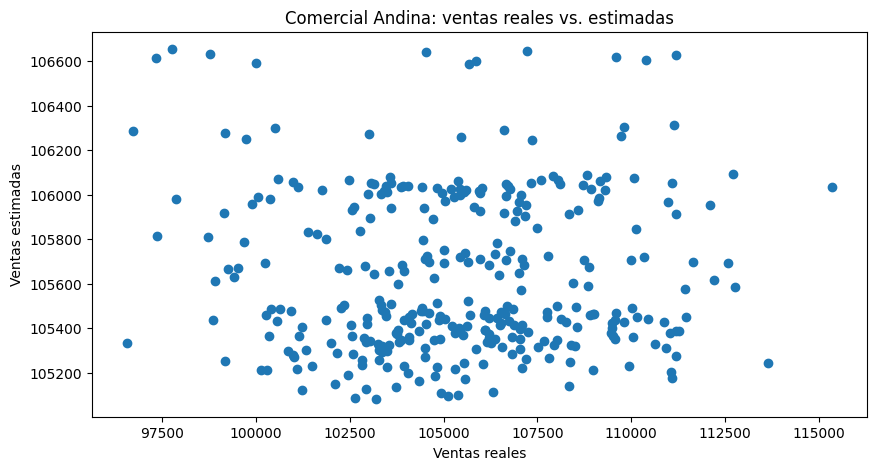

In [250]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    resultados['Ventas reales'],
    resultados['Ventas estimadas']
)

plt.xlabel('Ventas reales')
plt.ylabel('Ventas estimadas')
plt.title('Comercial Andina: ventas reales vs. estimadas')
plt.show()

In [251]:
referencia = ventas_semanales.sort_values(
    ['sucursal', 'categoria', 'inicio_semana']
).copy()

referencia['pronostico_anterior'] = referencia.groupby(
    ['sucursal', 'categoria']
)['ventas_totales'].shift(1)

In [252]:
referencia['semana'] = referencia['inicio_semana'].dt.isocalendar().week.astype(int)

referencia_test = referencia.loc[
    (referencia['semana'] > 41) &
    (referencia['dias_registrados'] == 7)
]

referencia_test.head()

,inicio_semana,sucursal,categoria,ventas_totales,transacciones,dias_registrados,pronostico_anterior,semana
1230,2025-10-13,Ambato-Centro,Alimentos,103534.05,1279,7,101175.57,42
1260,2025-10-20,Ambato-Centro,Alimentos,99265.97,1209,7,103534.05,43
1290,2025-10-27,Ambato-Centro,Alimentos,102218.98,1232,7,99265.97,44
1320,2025-11-03,Ambato-Centro,Alimentos,102914.53,1262,7,102218.98,45
1350,2025-11-10,Ambato-Centro,Alimentos,106202.61,1285,7,102914.53,46


In [253]:
mae_referencia = mean_absolute_error(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
)

rmse_referencia = mean_squared_error(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
) ** 0.5

r2_referencia = r2_score(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
)

print("MAE referencia:", round(mae_referencia, 2))
print("RMSE referencia:", round(rmse_referencia, 2))
print("R² referencia:", round(r2_referencia, 4))

MAE referencia: 3717.0
RMSE referencia: 4612.89
R² referencia: -0.8595


In [254]:
comparacion = pd.DataFrame({
    'Modelo': ['Regresión lineal', 'Semana anterior'],
    'MAE': [mae, mae_referencia],
    'RMSE': [rmse, rmse_referencia],
    'R²': [r2, r2_referencia]
})

comparacion

,Modelo,MAE,RMSE,R²
0,Regresión lineal,2714.138597,3414.301707,-0.018696
1,Semana anterior,3717.000364,4612.885997,-0.859458


In [255]:
referencia = ventas_modelo

In [256]:
referencia = ventas_semanales.sort_values(
    ['sucursal', 'categoria', 'inicio_semana']
).copy()

referencia['pronostico_anterior'] = referencia.groupby(
    ['sucursal', 'categoria']
)['ventas_totales'].shift(1)

In [257]:
referencia['semana'] = referencia['inicio_semana'].dt.isocalendar().week.astype(int)

referencia_test = referencia.loc[
    (referencia['semana'] > 41) &
    (referencia['dias_registrados'] == 7)
]

print(referencia_test.shape)

(330, 8)


In [258]:
mae_referencia = mean_absolute_error(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
)

rmse_referencia = mean_squared_error(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
) ** 0.5

r2_referencia = r2_score(
    referencia_test['ventas_totales'],
    referencia_test['pronostico_anterior']
)

print("MAE referencia:", round(mae_referencia, 2))
print("RMSE referencia:", round(rmse_referencia, 2))
print("R² referencia:", round(r2_referencia, 4))

MAE referencia: 3717.0
RMSE referencia: 4612.89
R² referencia: -0.8595


In [259]:
comparacion = pd.DataFrame({
    'Modelo': ['Regresión lineal', 'Semana anterior'],
    'MAE': [mae, mae_referencia],
    'RMSE': [rmse, rmse_referencia],
    'R²': [r2, r2_referencia]
})

comparacion

,Modelo,MAE,RMSE,R²
0,Regresión lineal,2714.138597,3414.301707,-0.018696
1,Semana anterior,3717.000364,4612.885997,-0.859458


In [260]:
promedio_historico = y_train.mean()

print("Promedio histórico:", round(promedio_historico, 2))

Promedio histórico: 105462.52


In [261]:
pred_promedio = [promedio_historico] * len(y_test)

mae_promedio = mean_absolute_error(y_test, pred_promedio)

rmse_promedio = mean_squared_error(y_test, pred_promedio) ** 0.5

print("MAE promedio:", round(mae_promedio, 2))
print("RMSE promedio:", round(rmse_promedio, 2))

MAE promedio: 2708.25
RMSE promedio: 3383.43


In [262]:
comparacion_final = pd.DataFrame({
    'Modelo': [
        'Regresión lineal',
        'Semana anterior',
        'Promedio histórico'
    ],
    'MAE': [mae, mae_referencia, mae_promedio],
    'RMSE': [rmse, rmse_referencia, rmse_promedio]
})

comparacion_final

,Modelo,MAE,RMSE
0,Regresión lineal,2714.138597,3414.301707
1,Semana anterior,3717.000364,4612.885997
2,Promedio histórico,2708.249378,3383.433874


La regresión lineal desarrollada no demostró una mejora predictiva frente al promedio histórico de entrenamiento. Por tanto, se recomienda continuar optimizando el modelo antes de utilizarlo como herramienta principal para la planificación comercial.

In [263]:
historico = ventas_semanales.loc[
    (ventas_semanales['inicio_semana'].dt.isocalendar().week <= 41) &
    (ventas_semanales['dias_registrados'] == 7)
]

promedio_grupo = historico.groupby(
    ['sucursal', 'categoria']
)['ventas_totales'].mean().reset_index()

promedio_grupo.columns = [
    'sucursal', 'categoria', 'pronostico_grupo'
]

promedio_grupo.head()

,sucursal,categoria,pronostico_grupo
0,Ambato-Centro,Alimentos,104919.39650
1,Ambato-Centro,Cuidado Personal,105655.88650
2,Ambato-Centro,Electrónica,105538.81875
3,Ambato-Centro,Hogar,105261.01175
4,Ambato-Centro,Limpieza,105692.00675


In [264]:
prueba_grupo = referencia_test.merge(
    promedio_grupo,
    on=['sucursal', 'categoria'],
    how='left'
)

prueba_grupo.head()

,inicio_semana,sucursal,categoria,ventas_totales,transacciones,dias_registrados,pronostico_anterior,semana,pronostico_grupo
0,2025-10-13,Ambato-Centro,Alimentos,103534.05,1279,7,101175.57,42,104919.3965
1,2025-10-20,Ambato-Centro,Alimentos,99265.97,1209,7,103534.05,43,104919.3965
2,2025-10-27,Ambato-Centro,Alimentos,102218.98,1232,7,99265.97,44,104919.3965
3,2025-11-03,Ambato-Centro,Alimentos,102914.53,1262,7,102218.98,45,104919.3965
4,2025-11-10,Ambato-Centro,Alimentos,106202.61,1285,7,102914.53,46,104919.3965


In [265]:
mae_grupo = mean_absolute_error(
    prueba_grupo['ventas_totales'],
    prueba_grupo['pronostico_grupo']
)

rmse_grupo = mean_squared_error(
    prueba_grupo['ventas_totales'],
    prueba_grupo['pronostico_grupo']
) ** 0.5

print("MAE por grupo:", round(mae_grupo, 2))
print("RMSE por grupo:", round(rmse_grupo, 2))

MAE por grupo: 2723.55
RMSE por grupo: 3426.84


In [266]:
comparacion_final = pd.DataFrame({
    'Modelo': [
        'Regresión lineal',
        'Semana anterior',
        'Promedio histórico',
        'Promedio por sucursal y categoría'
    ],
    'MAE': [
        mae, mae_referencia,
        mae_promedio, mae_grupo
    ],
    'RMSE': [
        rmse, rmse_referencia,
        rmse_promedio, rmse_grupo
    ]
})

comparacion_final

,Modelo,MAE,RMSE
0,Regresión lineal,2714.138597,3414.301707
1,Semana anterior,3717.000364,4612.885997
2,Promedio histórico,2708.249378,3383.433874
3,Promedio por sucursal y categoría,2723.553373,3426.837278


Conclusión de la evaluación predictiva

Se evaluaron cuatro métodos de pronóstico de ventas semanales utilizando 330 observaciones de prueba. El promedio histórico obtuvo el menor error absoluto promedio (MAE = $2.708,25) y la menor raíz del error cuadrático medio (RMSE = $3.383,43).

La regresión lineal presentó resultados cercanos, pero no superó al método de referencia. En consecuencia, no se justifica todavía su implementación como herramienta principal de pronóstico. Se recomienda ampliar el período histórico, incorporar variables comerciales relevantes y realizar nuevas validaciones temporales.

In [267]:
import numpy as np
from scipy import stats

errores = abs(y_test.to_numpy() - y_pred)

print("Cantidad de errores:", len(errores))
print("Error promedio:", round(errores.mean(), 2))

Cantidad de errores: 330
Error promedio: 2714.14


In [268]:
intervalo = stats.t.interval(
    0.95,
    df=len(errores) - 1,
    loc=errores.mean(),
    scale=stats.sem(errores)
)

print("Límite inferior:", round(intervalo[0], 2))
print("Límite superior:", round(intervalo[1], 2))

Límite inferior: 2489.48
Límite superior: 2938.8


In [269]:
errores_promedio = abs(
    y_test.to_numpy() - promedio_historico
)

diferencias = errores - errores_promedio

t, p_valor = stats.ttest_1samp(diferencias, 0)

print("Diferencia promedio:", round(diferencias.mean(), 2))
print("Valor p:", round(p_valor, 4))

Diferencia promedio: 5.89
Valor p: 0.7825


Conclusiones y recomendaciones – Comercial Andina

Objetivo del proyecto: Analizar las ventas históricas de Comercial Andina y evaluar métodos para pronosticar ventas semanales por sucursal y categoría, como apoyo a la planificación comercial.

Resultados principales

Se procesaron 2.000.000 de transacciones correspondientes al año 2025. Después de validar y consolidar la información, se utilizaron 1.530 observaciones semanales completas para la evaluación predictiva.

Se compararon cuatro métodos. El promedio histórico obtuvo el menor MAE ($2.708,25), seguido de la regresión lineal ($2.714,14). La diferencia fue de $5,89 por observación.

La regresión lineal presentó un R² de -0,0187, lo que indica que no consiguió explicar adecuadamente la variación de las ventas en el período de prueba.

Tres recomendaciones estratégicas

Planificación comercial: utilizar el promedio histórico como referencia provisional, considerando su margen de error y evitando decisiones automáticas de inventario.

Calidad y ampliación de datos: incorporar más años de información, calendario de promociones, feriados y datos de inventario para mejorar los pronósticos.

Control de desempeño: comparar semanalmente ventas reales y estimadas mediante MAE y RMSE antes de adoptar un modelo predictivo.

Tres próximos pasos

Validar los resultados con las áreas Comercial y Financiera.

Realizar una prueba piloto de seguimiento semanal.

Reentrenar y evaluar el modelo cuando se disponga de mayor información.

Limitaciones: el análisis utiliza un solo año de datos, no incluye inventarios ni cantidades vendidas y presenta descuentos promocionales faltantes. Por ello, los resultados no permiten cuantificar directamente ahorros de inventario o incrementos de rentabilidad.

Interpretación de las pruebas estadísticas

La regresión lineal obtuvo un MAE de $2.714,14. El intervalo de confianza aproximado del 95 % para el error absoluto medio fue de $2.489,48 a $2.938,80, bajo los supuestos de independencia de la prueba.

Al comparar la regresión lineal con el promedio histórico, se obtuvo un valor p de 0,7825. Como este resultado supera el nivel de significancia de 0,05, no se encontró evidencia estadística suficiente para afirmar que ambos métodos presentan errores medios diferentes.

Por tanto, se recomienda utilizar provisionalmente el promedio histórico como referencia comercial, sin implementar todavía la regresión lineal como herramienta principal de pronóstico.

Los resultados deben interpretarse con cautela debido a que las observaciones semanales están relacionadas y únicamente se dispone de un año de información.